# 05 · The paper figure

This notebook assembles the structure-function / shape figure from the pieces
built in notebooks 00-04, at the Science double-column width (7.25 in).

| Panel | Content | Built in |
|---|---|---|
| A | epochs 2, 3, 4 as R, G, B; the 46 windows; Regions 1 and 2; Region 2's drift | 00, 01, 04 |
| B, D | Region 1 (fixed) and Region 2 (co-moving), zoomed | 04 |
| C, E | PSF-deconvolved in-plane S2 in nine wedges, and S2 along W | 02, 04 |
| F | a3/a2 vs a2/a1 of every window, upper limits, common shape | 02, 03 |

`mabsf.figures.science_figure(cfg)` draws it; `cfg.calib` selects the PSF
calibration ('dedup' by default; 'published' reproduces the figure as first
submitted).

wrote figures/science_fig_sf_shape.pdf | 7.25 x 6.32 in


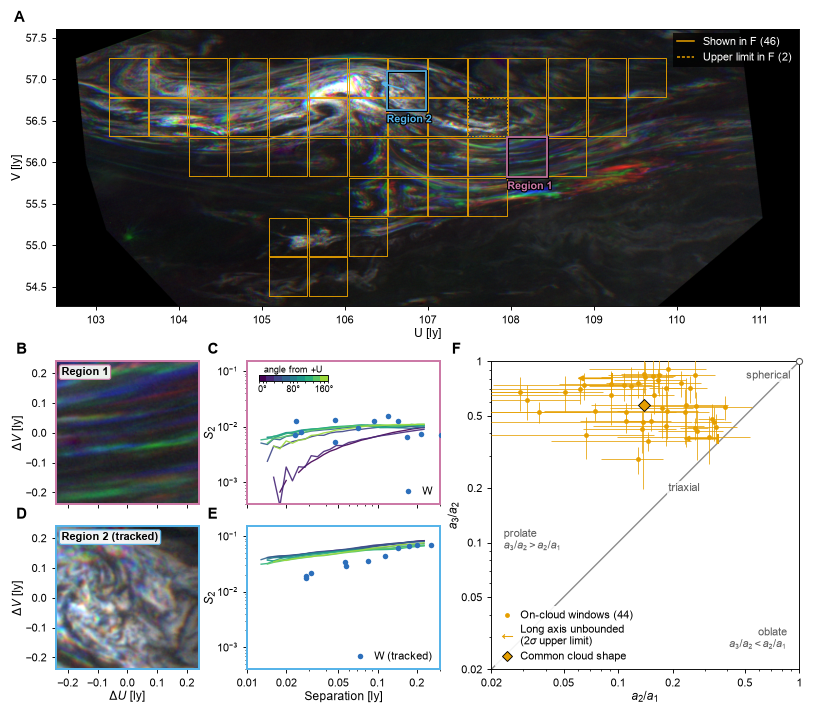

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os
from mabsf import config as C, data as D, figures as FG, shape as S
from mabsf.checks import check, targets

cfg = C.Config()
fig = FG.science_figure(cfg)
pdf, png = FG.save(fig)
print('wrote', os.path.relpath(pdf, D.REPO), '| %.2f x %.2f in' % fig.panel_data['size_in'])

**Caption notes.**
* A: epochs 2, 3 and 4 in red, green and blue; grey/white structure is the same
  in all three.  Orange: the 46 analysis windows (0.48 ly); dashed: windows
  whose long axis is unbounded (upper limits in F).  Arrow: Region 2's drift
  over the 0.55 ly depth range.
* C, E: S2 corrected for the PSF to an effective resolution of ~0.011 ly.
  Lines: in-plane S2 in 20-deg wedges of direction (key in C).  Points: S2
  between epochs, at their depth separation (co-moving window in E).
* F: PSF-corrected axis ratios with jackknife errors; diamond: the common
  shape from the variance-ratio fit (notebook 03).

## What is drawn in F

Panel F's axes start at 0.02, the collapse threshold, so every window with a
bounded long axis is drawn; the two unbounded ones appear as upper limits.

In [2]:
k = fig.panel_data['windows']; drawn = fig.panel_data['drawn']
bounded = k[S.usable(k) & ~k.collapsed]
print('windows %d = drawn %d + upper limits %d' % (len(k), len(drawn), int(k.collapsed.sum())))
check('F: every bounded window drawn', len(drawn), len(bounded), rtol=0)

windows 46 = drawn 44 + upper limits 2
ok   F: every bounded window drawn                    44  (expected 44)


## Checks

The figure is rebuilt as first submitted (stationary S2 estimator, 'published'
calibration) and its plotted data compared with the original figure's inputs.

In [3]:
figp = FG.science_figure(C.FIRST_SUBMISSION.replace(calib='published'))
T = targets(); W = pd.read_csv('../validation/targets_windows.csv')
dp = figp.panel_data['drawn'].merge(W, on=['row', 'col'])
check('F: plotted a2/a1 (published calibration)', dp.a2a1.values, dp.a2a1_base.values, rtol=1e-9)
check('F: plotted a3/a2 (published calibration)', dp.a3a2.values, dp.a3a2_base.values, rtol=1e-9)
sp = figp.panel_data['summary']
check('F: common shape (published)', [sp['common_a2a1'], sp['common_a3a2']],
      [T['population_base']['common_a2a1'], T['population_base']['common_a3a2']], rtol=1e-6)
check('F: upper limits (published)', sorted(S.upper_limits(figp.panel_data['windows']).values()),
      sorted(T['population_base']['upper_limits_a2a1'].values()), rtol=1e-6)
check('A: Region 2 drift arrow', figp.panel_data['velocity'], T['regions']['R2_velocity'], rtol=1e-12)
A = np.load('../validation/targets_arrays.npz')
for i in (1, 2):
    check('C/E: Region %d wedge profiles' % i, figp.panel_data['regions'][i]['prof'], A['R%d_prof' % i], rtol=1e-10)
    check('C/E: Region %d W points' % i, figp.panel_data['regions'][i]['w_s2'], A['R%d_ws2' % i], rtol=1e-10)
check('figure size [in]', figp.panel_data['size_in'], (7.25, 6.3166), rtol=1e-4)
plt.close(figp)

ok   F: plotted a2/a1 (published calibration)         [43 values, max |diff| 9.7e-17]  (expected )
ok   F: plotted a3/a2 (published calibration)         [43 values, max |diff| 1.1e-16]  (expected )
ok   F: common shape (published)                      [0.19119 0.56548]  (expected [0.19119 0.56548])
ok   F: upper limits (published)                      [0.11612 0.61383 1.     ]  (expected [0.11612 0.61383 1.     ])
ok   A: Region 2 drift arrow                          [-0.63388  0.17713]  (expected [-0.63388  0.17713])
ok   C/E: Region 1 wedge profiles                     [351 values, max |diff| 0]  (expected )
ok   C/E: Region 1 W points                           [21 values, max |diff| 0]  (expected )
ok   C/E: Region 2 wedge profiles                     [351 values, max |diff| 0]  (expected )
ok   C/E: Region 2 W points                           [21 values, max |diff| 0]  (expected )
ok   figure size [in]                                 [7.25   6.3166]  (expected [7.25   6.3166])
